In [125]:
import datajoint as dj
import datetime
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

from djimaging.user.amacrine_cells_neuromodulation.notebooks.helper_save_function import save_with_meta
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [128]:
current_date = datetime.date.today().strftime("%Y%m%d")
print(current_date)

20261012


In [3]:
df = pd.read_pickle(f"../datasets/Clustering.pkl")
df.head()

,experimenter,date,exp_num,raw_id,field,region,cond1,cond2,roi_id,preprocess_id_x_gChirp,...,os_index_movingbar,os_pvalue_movingbar,pref_or_movingbar,on_off_movingbar,d_qi_movingbar,dir_component_movingbar,time_component_movingbar,time_component_dt_movingbar,surrogate_v_movingbar,surrogate_dsi_movingbar
0,Salomon,2025-09-08,2,1,XY1,RR,v,C1,1,1,...,0.276144,0.29,1.251740,-0.30,0.424169,"[0.2692992, 0.21163529, 1.0, 0.0, 0.5561289, 0...","[0.26338604, -0.32434568, 0.50420314, 0.173609...",0.128,"[0.40229368, 0.0, 1.0, 0.22974569, 0.2547209, ...",0.099733
1,Salomon,2025-09-08,2,1,XY1,RR,v,C1,2,1,...,0.154824,0.58,2.867670,-0.06,0.573542,"[0.57404375, 0.5936899, 0.0, 0.09891763, 0.595...","[0.23134468, 0.12591584, -0.19623627, 0.122565...",0.128,"[0.71617424, 0.42367765, 0.0, 0.07766017, 0.33...",0.477601
2,Salomon,2025-09-08,2,1,XY1,RR,v,C1,3,1,...,0.483200,0.02,0.861053,-0.24,0.425207,"[0.35994393, 0.4662192, 0.58913016, 0.14168158...","[0.47586474, -0.5384664, -0.35983962, -0.44003...",0.128,"[0.3359132, 0.3226042, 0.47080025, 0.0, 0.3162...",0.222633
3,Salomon,2025-09-08,2,1,XY1,RR,v,C1,4,1,...,0.158540,0.43,0.351112,0.12,0.508752,"[0.05255287, 1.0, 0.0, 0.9599831, 0.82622796, ...","[-0.6013447, 0.066103116, 0.07772926, 0.050788...",0.128,"[0.35936928, 0.6933557, 0.0, 1.0, 0.77427435, ...",0.087994
4,Salomon,2025-09-08,2,1,XY1,RR,v,C1,5,1,...,0.059757,0.77,2.606700,-0.04,0.386349,"[0.09850365, 0.63157904, 0.0, 0.045831554, 0.4...","[0.06198706, 0.373452, 0.6631308, -0.64670223,...",0.128,"[0.2739429, 0.9214205, 0.08431966, 0.12541033,...",0.238921


In [5]:
df_c1 = df[df["cond2"] == "C1"]

In [7]:
# Determine the set of cond2 values per (date, field) group
group_conditions = df.groupby(["date", "field"])["cond2"].apply(lambda s: set(s.unique()))

# Identify which groups are C1/C2 vs C1/DETANO
c1_c2_groups = group_conditions[group_conditions == {"C1", "C2"}].index
c1_detano_groups = group_conditions[group_conditions == {"C1", "DETANO"}].index

# Build a boolean mask using the (date, field) MultiIndex
df_idx = df.set_index(["date", "field"]).index

df_c1_c2_chirp = df[df_idx.isin(c1_c2_groups)]
df_c1_detano_chirp = df[df_idx.isin(c1_detano_groups)]

print(f"C1/C2 groups: {len(c1_c2_groups)}")
print(f"C1/DETANO groups: {len(c1_detano_groups)}")

C1/C2 groups: 8
C1/DETANO groups: 9


In [6]:
dates = df["date"].unique()

for date in dates:

    df_date = df_c1[df_c1["date"] == date]
    fields = df_date["field"].unique()

    for field in fields:

        df_field = df_date[df_date["field"] == field]
        cond2 = df_field["cond2"].unique()

        df_field_filtered = df_field[df_field["qidx_gChirp"] > 0.35]

        print(f"{date}; {field}: Filtered: {len(df_field_filtered)}, All: {len(df_field)}, In %: {np.round(len(df_field_filtered)/len(df_field)*100, 0)}")

2025-09-08; XY1: Filtered: 6, All: 93, In %: 6.0
2025-09-08; XY2: Filtered: 61, All: 187, In %: 33.0
2025-09-08; XY3: Filtered: 84, All: 134, In %: 63.0
2025-09-08; XY4: Filtered: 8, All: 160, In %: 5.0
2025-09-08; XY6: Filtered: 28, All: 149, In %: 19.0
2025-09-08; XY7: Filtered: 246, All: 249, In %: 99.0
2025-09-08; XY8: Filtered: 221, All: 258, In %: 86.0
2025-10-23; XY7: Filtered: 147, All: 177, In %: 83.0
2025-10-23; XY8: Filtered: 13, All: 183, In %: 7.0
2025-10-23; XY1: Filtered: 1, All: 167, In %: 1.0
2025-10-23; XY2: Filtered: 71, All: 163, In %: 44.0
2025-10-23; XY3: Filtered: 25, All: 113, In %: 22.0
2025-10-23; XY4: Filtered: 189, All: 189, In %: 100.0
2025-10-23; XY5: Filtered: 177, All: 182, In %: 97.0
2025-10-23; XY6: Filtered: 154, All: 166, In %: 93.0
2025-11-19; XY4: Filtered: 187, All: 187, In %: 100.0
2025-11-19; XY5: Filtered: 0, All: 187, In %: 0.0


In [8]:
# Quality threshold for individual recordings
qidx_threshold = 0.35

# Minimum fraction of recordings that need to pass
quality_threshold = 0.30

# Calculate quality for each date-field pair
field_quality = (
    df_c1
    .assign(passes_quality=df_c1["qidx_gChirp"] > qidx_threshold)
    .groupby(["date", "field"])["passes_quality"]
    .mean()
)

# Keep only date-field pairs with >= 30% good recordings
good_fields = field_quality[field_quality >= quality_threshold].index

# Filter the original dataframe
df_c1_filtered = (
    df_c1.set_index(["date", "field"])
         .loc[good_fields]
         .reset_index()
)

print(f"Original rows: {len(df_c1)}")
print(f"Filtered rows: {len(df_c1_filtered)}")

Original rows: 2944
Filtered rows: 1892


In [13]:
keys = [
    "experimenter", "date", "exp_num", "raw_id",
    "field", "region", "cond1", "roi_id"
]

# 2. Retrieve the unique identifiers of the selected ROIs
selected_rois = df_c1_filtered[keys].drop_duplicates()

# 3. Retrieve all cond2 conditions for those same ROIs
df_all_conditions = df.merge(
    selected_rois,
    on=keys,
    how="inner"
)

In [24]:
# Determine the set of cond2 values per (date, field) group
group_conditions = df_all_conditions.groupby(["date", "field"])["cond2"].apply(lambda s: set(s.unique()))

# Identify which groups are C1/C2 vs C1/DETANO
c2_groups = group_conditions[group_conditions == {"C1", "C2"}].index
detano_groups = group_conditions[group_conditions == {"C1", "DETANO"}].index

# Build a boolean mask using the (date, field) MultiIndex
df_idx = df_all_conditions.set_index(["date", "field"]).index

df_c2 = df_all_conditions[df_idx.isin(c1_c2_groups)]
df_detano = df_all_conditions[df_idx.isin(c1_detano_groups)]

print(f"C1/C2 groups: {len(c2_groups)}")
print(f"C1/DETANO groups: {len(detano_groups)}")

C1/C2 groups: 5
C1/DETANO groups: 5


In [25]:
print(len(df_all_conditions))
print(len(df_c1_filtered))#*2)

3784
1892


In [27]:
print(len(df_c2))
print(len(df_detano))
print(len(df_c2) + len(df_detano))

1858
1926
3784


# C1/C2

## Global Chirp QI

In [30]:
dates = df_c2["date"].unique()

for date in dates:

    df_date = df_c2[df_c2["date"] == date]
    fields = df_date["field"].unique()

    for field in fields:

        df_field = df_date[df_date["field"] == field]
        cond2 = df_field["cond2"].unique()

        print(f"{date}; {field}: {cond2}")
    
    #print(f"{date}: {fields}")

2025-09-08; XY3: ['C1' 'C2']
2025-09-08; XY7: ['C1' 'C2']
2025-10-23; XY7: ['C1' 'C2']
2025-10-23; XY5: ['C1' 'C2']
2025-11-19; XY4: ['C1' 'C2']


In [32]:
df_c1_from_c2 = df_c2[df_c2["cond2"] == "C1"]
df_c2_from_c2 = df_c2[df_c2["cond2"] == "C2"]

print(len(df_c1_from_c2))
print(len(df_c2_from_c2))

929
929


In [33]:
threshold = 0.35

df_c1_from_c2_GC_thresh = df_c1_from_c2[df_c1_from_c2["qidx_gChirp"] > threshold]
df_c2_from_c2_GC_thresh = df_c2_from_c2[df_c2_from_c2["qidx_gChirp"] > threshold]

print(len(df_c1_from_c2_GC_thresh))
print(len(df_c2_from_c2_GC_thresh))

841
667


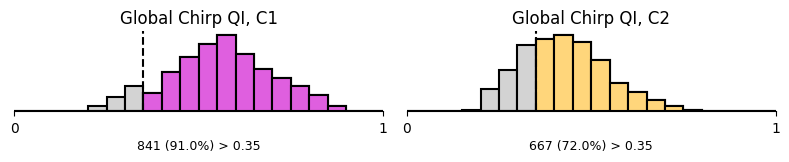

In [49]:
fig, axs = plt.subplots(1, 2, figsize=(8, 1.8))

bin_width = 0.05
bins = np.arange(0, 1 + bin_width, bin_width)

### C1 FIRST PLOT ###

axs[0].hist(df_c1_from_c2["qidx_gChirp"], bins=bins,
            color="lightgrey", alpha=1, edgecolor="black", linewidth=1.5)
axs[0].hist(df_c1_from_c2_GC_thresh["qidx_gChirp"], bins=bins,
            color="#df5fdfff", alpha=1, edgecolor="black", linewidth=1.5)

axs[0].set_xlim(0, 1)
axs[0].axvline(threshold, color="black", linestyle="--", linewidth=1.5)

percent_above = np.round(
    len(df_c1_from_c2_GC_thresh) / len(df_c1_from_c2) * 100, 0
)

axs[0].text(
    0.5, -0.35,
    f"{len(df_c1_from_c2_GC_thresh)} ({percent_above}%) > {threshold}",
    transform=axs[0].transAxes,
    ha="center", va="top", fontsize=9
)

for spine in ["top", "right", "left"]:
    axs[0].spines[spine].set_visible(False)

axs[0].set_yticks([])
axs[0].set_xticks([0, 1])
axs[0].set_title("Global Chirp QI, C1")


### C2 SECOND PLOT ###

axs[1].hist(df_c2_from_c2["qidx_gChirp"], bins=bins,
            color="lightgrey", alpha=1, edgecolor="black", linewidth=1.5)
axs[1].hist(df_c2_from_c2_GC_thresh["qidx_gChirp"], bins=bins,
            color="#ffd67bff", alpha=1, edgecolor="black", linewidth=1.5)

axs[1].set_xlim(0, 1)
axs[1].axvline(threshold, color="black", linestyle="--", linewidth=1.5)

percent_above = np.round(
    len(df_c2_from_c2_GC_thresh) / len(df_c2_from_c2) * 100, 0
)

axs[1].text(
    0.5, -0.35,
    f"{len(df_c2_from_c2_GC_thresh)} ({percent_above}%) > {threshold}",
    transform=axs[1].transAxes,
    ha="center", va="top", fontsize=9
)

for spine in ["top", "right", "left"]:
    axs[1].spines[spine].set_visible(False)

axs[1].set_yticks([])
axs[1].set_xticks([0, 1])
axs[1].set_title("Global Chirp QI, C2")

plt.tight_layout()
plt.subplots_adjust(bottom=0.35)

plt.savefig(f"../plots/qi/C1C2_histogram_gChirp.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

## Local chirp

In [42]:
df_c1_from_c2_LC_thresh = df_c1_from_c2[df_c1_from_c2["qidx_lChirp"] > threshold]
df_c2_from_c2_LC_thresh = df_c2_from_c2[df_c2_from_c2["qidx_lChirp"] > threshold]

print(len(df_c1_from_c2_LC_thresh))
print(len(df_c2_from_c2_LC_thresh))

278
62


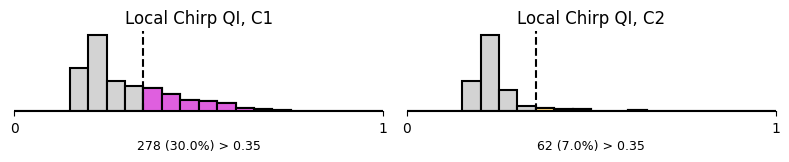

In [50]:
fig, axs = plt.subplots(1, 2, figsize=(8, 1.8))

bin_width = 0.05
bins = np.arange(0, 1 + bin_width, bin_width)

### C1 FIRST PLOT ###

axs[0].hist(df_c1_from_c2["qidx_lChirp"], bins=bins,
            color="lightgrey", alpha=1, edgecolor="black", linewidth=1.5)
axs[0].hist(df_c1_from_c2_LC_thresh["qidx_lChirp"], bins=bins,
            color="#df5fdfff", alpha=1, edgecolor="black", linewidth=1.5)

axs[0].set_xlim(0, 1)
axs[0].axvline(threshold, color="black", linestyle="--", linewidth=1.5)

percent_above = np.round(
    len(df_c1_from_c2_LC_thresh) / len(df_c1_from_c2) * 100, 0
)

axs[0].text(
    0.5, -0.35,
    f"{len(df_c1_from_c2_LC_thresh)} ({percent_above}%) > {threshold}",
    transform=axs[0].transAxes,
    ha="center", va="top", fontsize=9
)

for spine in ["top", "right", "left"]:
    axs[0].spines[spine].set_visible(False)

axs[0].set_yticks([])
axs[0].set_xticks([0, 1])
axs[0].set_title("Local Chirp QI, C1")


### C2 SECOND PLOT ###

axs[1].hist(df_c2_from_c2["qidx_lChirp"], bins=bins,
            color="lightgrey", alpha=1, edgecolor="black", linewidth=1.5)
axs[1].hist(df_c2_from_c2_LC_thresh["qidx_lChirp"], bins=bins,
            color="#ffd67bff", alpha=1, edgecolor="black", linewidth=1.5)

axs[1].set_xlim(0, 1)
axs[1].axvline(threshold, color="black", linestyle="--", linewidth=1.5)

percent_above = np.round(
    len(df_c2_from_c2_LC_thresh) / len(df_c2_from_c2) * 100, 0
)

axs[1].text(
    0.5, -0.35,
    f"{len(df_c2_from_c2_LC_thresh)} ({percent_above}%) > {threshold}",
    transform=axs[1].transAxes,
    ha="center", va="top", fontsize=9
)

for spine in ["top", "right", "left"]:
    axs[1].spines[spine].set_visible(False)

axs[1].set_yticks([])
axs[1].set_xticks([0, 1])
axs[1].set_title("Local Chirp QI, C2")

plt.tight_layout()
plt.subplots_adjust(bottom=0.35)

plt.savefig(f"../plots/qi/C1C2_histogram_lChirp.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

## Local chirp

In [46]:
threshold_mb = 0.6

df_c1_from_c2_MB_thresh = df_c1_from_c2[df_c1_from_c2["d_qi_movingbar"] > threshold_mb]
df_c2_from_c2_MB_thresh = df_c2_from_c2[df_c2_from_c2["d_qi_movingbar"] > threshold_mb]

print(len(df_c1_from_c2_MB_thresh))
print(len(df_c2_from_c2_MB_thresh))

766
370


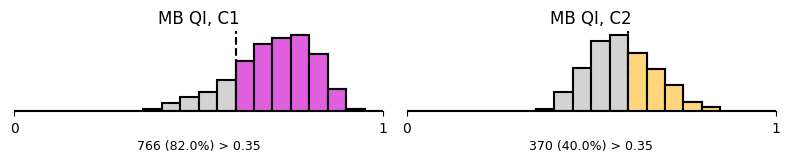

In [51]:
fig, axs = plt.subplots(1, 2, figsize=(8, 1.8))

bin_width = 0.05
bins = np.arange(0, 1 + bin_width, bin_width)

### C1 FIRST PLOT ###

axs[0].hist(df_c1_from_c2["d_qi_movingbar"], bins=bins,
            color="lightgrey", alpha=1, edgecolor="black", linewidth=1.5)
axs[0].hist(df_c1_from_c2_MB_thresh["d_qi_movingbar"], bins=bins,
            color="#df5fdfff", alpha=1, edgecolor="black", linewidth=1.5)

axs[0].set_xlim(0, 1)
axs[0].axvline(threshold_mb, color="black", linestyle="--", linewidth=1.5)

percent_above = np.round(
    len(df_c1_from_c2_MB_thresh) / len(df_c1_from_c2) * 100, 0
)

axs[0].text(
    0.5, -0.35,
    f"{len(df_c1_from_c2_MB_thresh)} ({percent_above}%) > {threshold}",
    transform=axs[0].transAxes,
    ha="center", va="top", fontsize=9
)

for spine in ["top", "right", "left"]:
    axs[0].spines[spine].set_visible(False)

axs[0].set_yticks([])
axs[0].set_xticks([0, 1])
axs[0].set_title("MB QI, C1")


### C2 SECOND PLOT ###

axs[1].hist(df_c2_from_c2["d_qi_movingbar"], bins=bins,
            color="lightgrey", alpha=1, edgecolor="black", linewidth=1.5)
axs[1].hist(df_c2_from_c2_MB_thresh["d_qi_movingbar"], bins=bins,
            color="#ffd67bff", alpha=1, edgecolor="black", linewidth=1.5)

axs[1].set_xlim(0, 1)
axs[1].axvline(threshold_mb, color="black", linestyle="--", linewidth=1.5)

percent_above = np.round(
    len(df_c2_from_c2_MB_thresh) / len(df_c2_from_c2) * 100, 0
)

axs[1].text(
    0.5, -0.35,
    f"{len(df_c2_from_c2_MB_thresh)} ({percent_above}%) > {threshold}",
    transform=axs[1].transAxes,
    ha="center", va="top", fontsize=9
)

for spine in ["top", "right", "left"]:
    axs[1].spines[spine].set_visible(False)

axs[1].set_yticks([])
axs[1].set_xticks([0, 1])
axs[1].set_title("MB QI, C2")

plt.tight_layout()
plt.subplots_adjust(bottom=0.35)

plt.savefig(f"../plots/qi/C1C2_histogram_MB.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

# C1/DETANO

## gChirp

In [53]:
dates = df_detano["date"].unique()

for date in dates:

    df_date = df_detano[df_detano["date"] == date]
    fields = df_date["field"].unique()

    for field in fields:

        df_field = df_date[df_date["field"] == field]
        cond2 = df_field["cond2"].unique()

        print(f"{date}; {field}: {cond2}")
    
    #print(f"{date}: {fields}")

2025-09-08; XY2: ['C1' 'DETANO']
2025-09-08; XY8: ['C1' 'DETANO']
2025-10-23; XY2: ['C1' 'DETANO']
2025-10-23; XY4: ['C1' 'DETANO']
2025-10-23; XY6: ['C1' 'DETANO']


In [56]:
df_c1_from_detano = df_detano[df_detano["cond2"] == "C1"]
df_detano_from_detano = df_detano[df_detano["cond2"] == "DETANO"]

print(len(df_c1_from_detano))
print(len(df_detano_from_detano))

963
963


In [58]:
threshold = 0.35

df_c1_from_detano_GC_thresh = df_c1_from_detano[df_c1_from_detano["qidx_gChirp"] > threshold]
df_detano_from_detano_GC_thresh = df_detano_from_detano[df_detano_from_detano["qidx_gChirp"] > threshold]

print(len(df_c1_from_detano_GC_thresh))
print(len(df_detano_from_detano_GC_thresh))

696
511


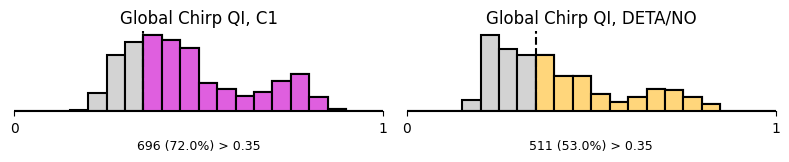

In [59]:
fig, axs = plt.subplots(1, 2, figsize=(8, 1.8))

bin_width = 0.05
bins = np.arange(0, 1 + bin_width, bin_width)

### C1 FIRST PLOT ###

axs[0].hist(df_c1_from_detano["qidx_gChirp"], bins=bins,
            color="lightgrey", alpha=1, edgecolor="black", linewidth=1.5)
axs[0].hist(df_c1_from_detano_GC_thresh["qidx_gChirp"], bins=bins,
            color="#df5fdfff", alpha=1, edgecolor="black", linewidth=1.5)

axs[0].set_xlim(0, 1)
axs[0].axvline(threshold, color="black", linestyle="--", linewidth=1.5)

percent_above = np.round(
    len(df_c1_from_detano_GC_thresh) / len(df_c1_from_detano) * 100, 0
)

axs[0].text(
    0.5, -0.35,
    f"{len(df_c1_from_detano_GC_thresh)} ({percent_above}%) > {threshold}",
    transform=axs[0].transAxes,
    ha="center", va="top", fontsize=9
)

for spine in ["top", "right", "left"]:
    axs[0].spines[spine].set_visible(False)

axs[0].set_yticks([])
axs[0].set_xticks([0, 1])
axs[0].set_title("Global Chirp QI, C1")


### DETA/NO SECOND PLOT ###

axs[1].hist(df_detano_from_detano["qidx_gChirp"], bins=bins,
            color="lightgrey", alpha=1, edgecolor="black", linewidth=1.5)
axs[1].hist(df_detano_from_detano_GC_thresh["qidx_gChirp"], bins=bins,
            color="#ffd67bff", alpha=1, edgecolor="black", linewidth=1.5)

axs[1].set_xlim(0, 1)
axs[1].axvline(threshold, color="black", linestyle="--", linewidth=1.5)

percent_above = np.round(
    len(df_detano_from_detano_GC_thresh) / len(df_detano_from_detano) * 100, 0
)

axs[1].text(
    0.5, -0.35,
    f"{len(df_detano_from_detano_GC_thresh)} ({percent_above}%) > {threshold}",
    transform=axs[1].transAxes,
    ha="center", va="top", fontsize=9
)

for spine in ["top", "right", "left"]:
    axs[1].spines[spine].set_visible(False)

axs[1].set_yticks([])
axs[1].set_xticks([0, 1])
axs[1].set_title("Global Chirp QI, DETA/NO")

plt.tight_layout()
plt.subplots_adjust(bottom=0.35)

plt.savefig(f"../plots/qi/C1DETANO_histogram_gChirp.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

## Local chirp

In [60]:
df_c1_from_detano_LC_thresh = df_c1_from_detano[df_c1_from_detano["qidx_lChirp"] > threshold]
df_detano_from_detano_LC_thresh = df_detano_from_detano[df_detano_from_detano["qidx_lChirp"] > threshold]

print(len(df_c1_from_detano_LC_thresh))
print(len(df_detano_from_detano_LC_thresh))

286
258


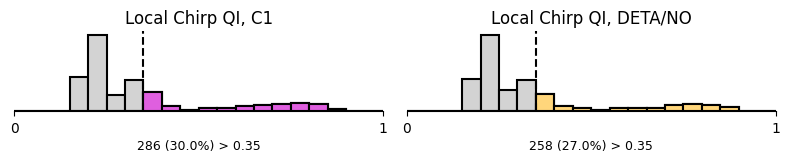

In [62]:
fig, axs = plt.subplots(1, 2, figsize=(8, 1.8))

bin_width = 0.05
bins = np.arange(0, 1 + bin_width, bin_width)

### C1 FIRST PLOT ###

axs[0].hist(df_c1_from_detano["qidx_lChirp"], bins=bins,
            color="lightgrey", alpha=1, edgecolor="black", linewidth=1.5)
axs[0].hist(df_c1_from_detano_LC_thresh["qidx_lChirp"], bins=bins,
            color="#df5fdfff", alpha=1, edgecolor="black", linewidth=1.5)

axs[0].set_xlim(0, 1)
axs[0].axvline(threshold, color="black", linestyle="--", linewidth=1.5)

percent_above = np.round(
    len(df_c1_from_detano_LC_thresh) / len(df_c1_from_detano) * 100, 0
)

axs[0].text(
    0.5, -0.35,
    f"{len(df_c1_from_detano_LC_thresh)} ({percent_above}%) > {threshold}",
    transform=axs[0].transAxes,
    ha="center", va="top", fontsize=9
)

for spine in ["top", "right", "left"]:
    axs[0].spines[spine].set_visible(False)

axs[0].set_yticks([])
axs[0].set_xticks([0, 1])
axs[0].set_title("Local Chirp QI, C1")


### DETA/NO SECOND PLOT ###

axs[1].hist(df_detano_from_detano["qidx_lChirp"], bins=bins,
            color="lightgrey", alpha=1, edgecolor="black", linewidth=1.5)
axs[1].hist(df_detano_from_detano_LC_thresh["qidx_lChirp"], bins=bins,
            color="#ffd67bff", alpha=1, edgecolor="black", linewidth=1.5)

axs[1].set_xlim(0, 1)
axs[1].axvline(threshold, color="black", linestyle="--", linewidth=1.5)

percent_above = np.round(
    len(df_detano_from_detano_LC_thresh) / len(df_detano_from_detano) * 100, 0
)

axs[1].text(
    0.5, -0.35,
    f"{len(df_detano_from_detano_LC_thresh)} ({percent_above}%) > {threshold}",
    transform=axs[1].transAxes,
    ha="center", va="top", fontsize=9
)

for spine in ["top", "right", "left"]:
    axs[1].spines[spine].set_visible(False)

axs[1].set_yticks([])
axs[1].set_xticks([0, 1])
axs[1].set_title("Local Chirp QI, DETA/NO")

plt.tight_layout()
plt.subplots_adjust(bottom=0.35)

plt.savefig(f"../plots/qi/C1DETANO_histogram_lChirp.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

## Local chirp

In [63]:
df_c1_from_detano_MB_thresh = df_c1_from_detano[df_c1_from_detano["d_qi_movingbar"] > threshold_mb]
df_detano_from_detano_MB_thresh = df_detano_from_detano[df_detano_from_detano["d_qi_movingbar"] > threshold_mb]

print(len(df_c1_from_detano_MB_thresh))
print(len(df_detano_from_detano_MB_thresh))

415
384


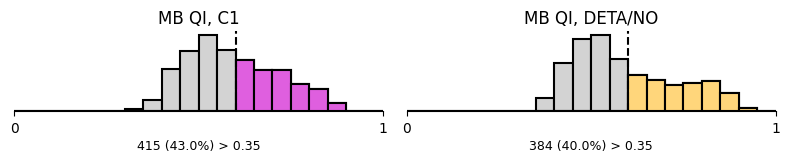

In [65]:
fig, axs = plt.subplots(1, 2, figsize=(8, 1.8))

bin_width = 0.05
bins = np.arange(0, 1 + bin_width, bin_width)

### C1 FIRST PLOT ###

axs[0].hist(df_c1_from_detano["d_qi_movingbar"], bins=bins,
            color="lightgrey", alpha=1, edgecolor="black", linewidth=1.5)
axs[0].hist(df_c1_from_detano_MB_thresh["d_qi_movingbar"], bins=bins,
            color="#df5fdfff", alpha=1, edgecolor="black", linewidth=1.5)

axs[0].set_xlim(0, 1)
axs[0].axvline(threshold_mb, color="black", linestyle="--", linewidth=1.5)

percent_above = np.round(
    len(df_c1_from_detano_MB_thresh) / len(df_c1_from_detano) * 100, 0
)

axs[0].text(
    0.5, -0.35,
    f"{len(df_c1_from_detano_MB_thresh)} ({percent_above}%) > {threshold}",
    transform=axs[0].transAxes,
    ha="center", va="top", fontsize=9
)

for spine in ["top", "right", "left"]:
    axs[0].spines[spine].set_visible(False)

axs[0].set_yticks([])
axs[0].set_xticks([0, 1])
axs[0].set_title("MB QI, C1")


### DETA/NO SECOND PLOT ###

axs[1].hist(df_detano_from_detano["d_qi_movingbar"], bins=bins,
            color="lightgrey", alpha=1, edgecolor="black", linewidth=1.5)
axs[1].hist(df_detano_from_detano_MB_thresh["d_qi_movingbar"], bins=bins,
            color="#ffd67bff", alpha=1, edgecolor="black", linewidth=1.5)

axs[1].set_xlim(0, 1)
axs[1].axvline(threshold_mb, color="black", linestyle="--", linewidth=1.5)

percent_above = np.round(
    len(df_detano_from_detano_MB_thresh) / len(df_detano_from_detano) * 100, 0
)

axs[1].text(
    0.5, -0.35,
    f"{len(df_detano_from_detano_MB_thresh)} ({percent_above}%) > {threshold}",
    transform=axs[1].transAxes,
    ha="center", va="top", fontsize=9
)

for spine in ["top", "right", "left"]:
    axs[1].spines[spine].set_visible(False)

axs[1].set_yticks([])
axs[1].set_xticks([0, 1])
axs[1].set_title("MB QI, DETA/NO")

plt.tight_layout()
plt.subplots_adjust(bottom=0.35)

plt.savefig(f"../plots/qi/C1DETANO_histogram_MB.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

# Filter dataset further

## C2

- QI in both conditions above certain threshold
- all three stimuli with OR
    - e.g., gChirp OR lChirp OR MB

In [66]:
# Check which conditions are present
print(df_c2["cond2"].value_counts(dropna=False))

cond2
C1    929
C2    929
Name: count, dtype: int64


In [76]:
# Columns that uniquely identify an ROI ACROSS conditions (adjust to your data!)
ID_COLS = [
    "experimenter", "date", "exp_num", "raw_id", "field",
    "region", "cond1", "roi_id"
]         # e.g. ["date", "field", "roi"]
COND_COL = "cond2"
CONDITIONS = ["C1", "C2"]

THR = {
    "qidx_gChirp": 0.3,
    "qidx_lChirp": 0.3,
    "d_qi_movingbar": 0.6,
}

In [77]:
print("Shape:", df.shape)
print("\nRows per condition:")
print(df_c2[COND_COL].value_counts(dropna=False))

print("\nMissing values in quality columns:")
print(df_c2[list(THR)].isna().sum())

# Each ROI should appear at most once per condition
dup = df.duplicated(subset=ID_COLS + [COND_COL], keep=False)
print("\nDuplicate (ID, condition) rows:", dup.sum())
assert dup.sum() == 0, "Some ROIs appear more than once per condition. Check ID_COLS!"

# How many ROIs are recorded in 1 vs 2 conditions to begin with?
print("\nNumber of conditions per ROI (before filtering):")
print(df_c2.groupby(ID_COLS)[COND_COL].nunique().value_counts())

Shape: (5888, 47)

Rows per condition:
cond2
C1    929
C2    929
Name: count, dtype: int64

Missing values in quality columns:
qidx_gChirp       0
qidx_lChirp       0
d_qi_movingbar    0
dtype: int64

Duplicate (ID, condition) rows: 0

Number of conditions per ROI (before filtering):
cond2
2    929
Name: count, dtype: int64


In [80]:
df_c2_filtered = df_c2.copy()
df_c2_filtered["passes_qi"] = (
    (df["qidx_gChirp"]    > THR["qidx_gChirp"]) |
    (df["qidx_lChirp"]    > THR["qidx_lChirp"]) |
    (df["d_qi_movingbar"] > THR["d_qi_movingbar"])
)
# Note: comparisons with NaN evaluate to False, so a NaN never counts as "passing"

print("Passing rows per condition:")
print(df_c2_filtered.groupby(COND_COL)["passes_qi"].agg(n_pass="sum", n_total="count", frac_pass="mean"))

# Eyeball a few rows to verify the logic
df_c2_filtered[ID_COLS + [COND_COL] + list(THR) + ["passes_qi"]].sample(10, random_state=0)

Passing rows per condition:
       n_pass  n_total  frac_pass
cond2                            
C1        773      929   0.832078
C2        652      929   0.701830


,experimenter,date,exp_num,raw_id,field,region,cond1,roi_id,cond2,qidx_gChirp,qidx_lChirp,d_qi_movingbar,passes_qi
1960,Salomon,2025-10-23,1,1,XY7,LR,t,128,C2,0.642046,0.235274,0.674685,True
847,Salomon,2025-09-08,2,1,XY7,RR,n,206,C1,0.509943,0.189430,0.725471,True
1913,Salomon,2025-10-23,1,1,XY7,LR,t,81,C2,0.498624,0.259694,0.636232,True
1119,Salomon,2025-09-08,2,1,XY7,RR,n,229,C2,0.443516,0.192152,0.527757,False
427,Salomon,2025-09-08,2,1,XY3,RR,t,54,C1,0.294137,0.365598,0.444054,True
1942,Salomon,2025-10-23,1,1,XY7,LR,t,110,C2,0.467233,0.257513,0.535009,True
2786,Salomon,2025-10-23,2,1,XY5,RR,n,73,C1,0.694644,0.659709,0.867416,True
392,Salomon,2025-09-08,2,1,XY3,RR,t,19,C1,0.472010,0.492112,0.534207,True
1886,Salomon,2025-10-23,1,1,XY7,LR,t,54,C2,0.208133,0.192912,0.433585,True
1685,Salomon,2025-10-23,1,1,XY7,LR,t,30,C1,0.472270,0.352464,0.820731,True


In [83]:
pass_table = (
    df_c2_filtered.pivot_table(index=ID_COLS, columns=COND_COL, values="passes_qi", aggfunc="any")
      .reindex(columns=CONDITIONS)
      .fillna(False)          # ROI missing in a condition counts as "not passing"
      .astype(bool)
)
pass_table["both"] = pass_table["C1"] & pass_table["C2"]

print("Cross-tab of passing in C1 (rows) vs C2 (columns):")
print(pd.crosstab(pass_table["C1"], pass_table["C2"]))

good_ids = pass_table.index[pass_table["both"]]
print("\nROIs passing in BOTH conditions:", len(good_ids))

Cross-tab of passing in C1 (rows) vs C2 (columns):
C2     False  True 
C1                 
False     55    101
True     222    551

ROIs passing in BOTH conditions: 551


In [84]:
row_ids = df_c2.set_index(ID_COLS).index
df_c2_filtered_thresh = df_c2[row_ids.isin(good_ids)].copy()

print("Before:", df_c2.shape, " After:", df_c2_filtered_thresh.shape)

Before: (1858, 47)  After: (1102, 47)


In [93]:
# Pick an ROI that passed in one condition but not the other, and look at its raw values
mixed = pass_table[pass_table["C1"] ^ pass_table["C2"]].index
if len(mixed) > 0:
    example = mixed[0]
    print("Example excluded ROI:", example)
    display(df_c2_filtered[row_ids == example][ID_COLS + [COND_COL] + list(THR) + ["passes_qi"]])

Example excluded ROI: ('Salomon', datetime.date(2025, 9, 8), 2, 1, 'XY3', 'RR', 't', 28)


,experimenter,date,exp_num,raw_id,field,region,cond1,roi_id,cond2,qidx_gChirp,qidx_lChirp,d_qi_movingbar,passes_qi
401,Salomon,2025-09-08,2,1,XY3,RR,t,28,C1,0.316488,0.388313,0.584307,True
535,Salomon,2025-09-08,2,1,XY3,RR,t,28,C2,0.284317,0.225303,0.489067,False


In [97]:
print(df_c2_filtered_thresh.columns.to_list())
print(df_c2_filtered_thresh.shape)

['experimenter', 'date', 'exp_num', 'raw_id', 'field', 'region', 'cond1', 'cond2', 'roi_id', 'preprocess_id_x_gChirp', 'average_gChirp', 'average_norm_gChirp', 'average_t0_gChirp', 'average_dt_gChirp', 'triggertimes_rel_gChirp', 'preprocess_id_y_gChirp', 'qidx_gChirp', 'min_qidx_gChirp', 'preprocess_id_x_lChirp', 'average_lChirp', 'average_norm_lChirp', 'average_t0_lChirp', 'average_dt_lChirp', 'triggertimes_rel_lChirp', 'preprocess_id_y_lChirp', 'qidx_lChirp', 'min_qidx_lChirp', 'preprocess_id_x_movingbar', 'average_movingbar', 'average_norm_movingbar', 'average_t0_movingbar', 'average_dt_movingbar', 'triggertimes_rel_movingbar', 'preprocess_id_y_movingbar', 'ds_index_movingbar', 'ds_pvalue_movingbar', 'pref_dir_movingbar', 'os_index_movingbar', 'os_pvalue_movingbar', 'pref_or_movingbar', 'on_off_movingbar', 'd_qi_movingbar', 'dir_component_movingbar', 'time_component_movingbar', 'time_component_dt_movingbar', 'surrogate_v_movingbar', 'surrogate_dsi_movingbar']
(1102, 47)


## DETA/NO

In [106]:
# Check which conditions are present
print(df_detano["cond2"].value_counts(dropna=False))

CONDITIONS = df_detano["cond2"].unique()
print(CONDITIONS)

cond2
C1        963
DETANO    963
Name: count, dtype: int64
['C1' 'DETANO']


In [99]:
print("Shape:", df.shape)
print("\nRows per condition:")
print(df_detano[COND_COL].value_counts(dropna=False))

print("\nMissing values in quality columns:")
print(df_detano[list(THR)].isna().sum())

# Each ROI should appear at most once per condition
dup = df.duplicated(subset=ID_COLS + [COND_COL], keep=False)
print("\nDuplicate (ID, condition) rows:", dup.sum())
assert dup.sum() == 0, "Some ROIs appear more than once per condition. Check ID_COLS!"

# How many ROIs are recorded in 1 vs 2 conditions to begin with?
print("\nNumber of conditions per ROI (before filtering):")
print(df_detano.groupby(ID_COLS)[COND_COL].nunique().value_counts())

Shape: (5888, 47)

Rows per condition:
cond2
C1        963
DETANO    963
Name: count, dtype: int64

Missing values in quality columns:
qidx_gChirp       0
qidx_lChirp       0
d_qi_movingbar    0
dtype: int64

Duplicate (ID, condition) rows: 0

Number of conditions per ROI (before filtering):
cond2
2    963
Name: count, dtype: int64


In [100]:
df_detano_filtered = df_detano.copy()
df_detano_filtered["passes_qi"] = (
    (df["qidx_gChirp"]    > THR["qidx_gChirp"]) |
    (df["qidx_lChirp"]    > THR["qidx_lChirp"]) |
    (df["d_qi_movingbar"] > THR["d_qi_movingbar"])
)
# Note: comparisons with NaN evaluate to False, so a NaN never counts as "passing"

print("Passing rows per condition:")
print(df_detano_filtered.groupby(COND_COL)["passes_qi"].agg(n_pass="sum", n_total="count", frac_pass="mean"))

# Eyeball a few rows to verify the logic
df_detano_filtered[ID_COLS + [COND_COL] + list(THR) + ["passes_qi"]].sample(10, random_state=0)

Passing rows per condition:
        n_pass  n_total  frac_pass
cond2                             
C1         658      963   0.683281
DETANO     788      963   0.818276


,experimenter,date,exp_num,raw_id,field,region,cond1,roi_id,cond2,qidx_gChirp,qidx_lChirp,d_qi_movingbar,passes_qi
3144,Salomon,2025-10-23,2,1,XY6,RR,n,67,C1,0.453095,0.232927,0.657221,False
2189,Salomon,2025-10-23,2,1,XY2,RR,d,17,DETANO,0.280739,0.198883,0.446810,True
156,Salomon,2025-09-08,2,1,XY2,RR,v,157,C1,0.273126,0.331448,0.491761,True
1445,Salomon,2025-09-08,2,1,XY8,RR,n,48,DETANO,0.384925,0.182284,0.575046,False
1191,Salomon,2025-09-08,2,1,XY8,RR,n,52,C1,0.412748,0.218823,0.685050,False
2133,Salomon,2025-10-23,2,1,XY2,RR,d,124,C1,0.275166,0.194440,0.478567,True
3391,Salomon,2025-10-23,2,1,XY6,RR,n,148,DETANO,0.281856,0.231953,0.569511,False
2573,Salomon,2025-10-23,2,1,XY4,RR,n,49,DETANO,0.695334,0.746425,0.837069,True
80,Salomon,2025-09-08,2,1,XY2,RR,v,81,C1,0.300616,0.349873,0.547907,True
223,Salomon,2025-09-08,2,1,XY2,RR,v,37,DETANO,0.218295,0.323911,0.432928,True


In [107]:
pass_table = (
    df_detano_filtered.pivot_table(index=ID_COLS, columns=COND_COL, values="passes_qi", aggfunc="any")
      .reindex(columns=CONDITIONS)
      .fillna(False)          # ROI missing in a condition counts as "not passing"
      .astype(bool)
)
pass_table["both"] = pass_table[str(CONDITIONS[0])] & pass_table[str(CONDITIONS[1])]

print(f"Cross-tab of passing in {CONDITIONS[0]} (rows) vs {CONDITIONS[1]} (columns):")
print(pd.crosstab(pass_table[str(CONDITIONS[0])], pass_table[str(CONDITIONS[1])]))

good_ids = pass_table.index[pass_table["both"]]
print("\nROIs passing in BOTH conditions:", len(good_ids))

Cross-tab of passing in C1 (rows) vs DETANO (columns):
DETANO  False  True 
C1                  
False      96    209
True       79    579

ROIs passing in BOTH conditions: 579


In [108]:
row_ids = df_detano.set_index(ID_COLS).index
df_detano_filtered_thresh = df_detano[row_ids.isin(good_ids)].copy()

print("Before:", df_detano.shape, " After:", df_detano_filtered_thresh.shape)

Before: (1926, 47)  After: (1158, 47)


In [109]:
# Pick an ROI that passed in one condition but not the other, and look at its raw values
mixed = pass_table[pass_table[str(CONDITIONS[0])] ^ pass_table[str(CONDITIONS[1])]].index
if len(mixed) > 0:
    example = mixed[0]
    print("Example excluded ROI:", example)
    display(df_detano_filtered[row_ids == example][ID_COLS + [COND_COL] + list(THR) + ["passes_qi"]])

Example excluded ROI: ('Salomon', datetime.date(2025, 9, 8), 2, 1, 'XY2', 'RR', 'v', 8)


,experimenter,date,exp_num,raw_id,field,region,cond1,roi_id,cond2,qidx_gChirp,qidx_lChirp,d_qi_movingbar,passes_qi
7,Salomon,2025-09-08,2,1,XY2,RR,v,8,C1,0.366679,0.335767,0.491576,False
194,Salomon,2025-09-08,2,1,XY2,RR,v,8,DETANO,0.273591,0.361846,0.391610,True


In [110]:
print(df_detano_filtered_thresh.columns.to_list())
print(df_detano_filtered_thresh.shape)

['experimenter', 'date', 'exp_num', 'raw_id', 'field', 'region', 'cond1', 'cond2', 'roi_id', 'preprocess_id_x_gChirp', 'average_gChirp', 'average_norm_gChirp', 'average_t0_gChirp', 'average_dt_gChirp', 'triggertimes_rel_gChirp', 'preprocess_id_y_gChirp', 'qidx_gChirp', 'min_qidx_gChirp', 'preprocess_id_x_lChirp', 'average_lChirp', 'average_norm_lChirp', 'average_t0_lChirp', 'average_dt_lChirp', 'triggertimes_rel_lChirp', 'preprocess_id_y_lChirp', 'qidx_lChirp', 'min_qidx_lChirp', 'preprocess_id_x_movingbar', 'average_movingbar', 'average_norm_movingbar', 'average_t0_movingbar', 'average_dt_movingbar', 'triggertimes_rel_movingbar', 'preprocess_id_y_movingbar', 'ds_index_movingbar', 'ds_pvalue_movingbar', 'pref_dir_movingbar', 'os_index_movingbar', 'os_pvalue_movingbar', 'pref_or_movingbar', 'on_off_movingbar', 'd_qi_movingbar', 'dir_component_movingbar', 'time_component_movingbar', 'time_component_dt_movingbar', 'surrogate_v_movingbar', 'surrogate_dsi_movingbar']
(1158, 47)


In [115]:
df_combined = pd.concat([df_c2_filtered_thresh, df_detano_filtered_thresh], axis=0)
df_combined.shape

(2260, 47)

In [121]:
print(len(df_combined[df_combined["qidx_gChirp"] > threshold]))
print(len(df_combined[(df_combined["cond2"] == "C1") & (df_combined["qidx_gChirp"] > threshold)]))
print(len(df_combined[(df_combined["cond2"] == "C1") & (df_combined["qidx_lChirp"] > threshold)]))
print(len(df_combined[(df_combined["cond2"] == "C1") & (df_combined["d_qi_movingbar"] > threshold_mb)]))

1503
834
381
666


In [122]:
print(len(df_combined[(df_combined["cond2"] == "C2") & (df_combined["qidx_gChirp"] > threshold)]))
print(len(df_combined[(df_combined["cond2"] == "C2") & (df_combined["qidx_lChirp"] > threshold)]))
print(len(df_combined[(df_combined["cond2"] == "C2") & (df_combined["d_qi_movingbar"] > threshold_mb)]))

373
51
219


In [123]:
print(len(df_combined[(df_combined["cond2"] == "DETANO") & (df_combined["qidx_gChirp"] > threshold)]))
print(len(df_combined[(df_combined["cond2"] == "DETANO") & (df_combined["qidx_lChirp"] > threshold)]))
print(len(df_combined[(df_combined["cond2"] == "DETANO") & (df_combined["d_qi_movingbar"] > threshold_mb)]))

296
209
207


In [127]:
### DEFINE JSON STATE AND SAVE DATAFRAME ###

description = ["Average traces from Ca imaging data from IPL, GAD65 x Ai95GCaMP, strictly filtered based on quality indices, lChirp OR gChirp > 0.35 for C1 and C2/NO OR MB QI > 0.6 for C1 and C2/NO"]
inputs = {"source": "qi_histograms.ipynb", "dataset": "../datasets/Raw/Averages_GAD65GCaMP6_20261012.pkl","restriction": "No restriction used here"}
params = {"stimuli": "gChirp, lChirp, MB",
          "filtering": "quality restriction as described in the description"}

In [129]:
save_with_meta(df=df_combined, path=f"../datasets/Processed/Averages_StrictlyQIFiltered_{current_date}.pkl",
               description=description,
               inputs=inputs,
               params=params)

In [124]:
df_combined.to_pickle(f"../datasets/Strictly_Filtered_All_Stimuli.pkl")